# Task 03 — Build Data Visualizations
## Iris Flower Dataset

**Goal:** Explore flower measurements and communicate patterns using at least five readable visualizations.

**Dataset:** `iris_flower_dataset.csv` — 150 flower records with sepal/petal measurements and species labels.

### Charts included
1. Bar chart — average petal length by species
2. Line chart — average measurements by species (ordered category comparison)
3. Pie chart — share of records by species
4. Histogram — distribution of petal length
5. Scatter plot — sepal length vs. petal length
6. Bonus: correlation heatmap

> Run the notebook from top to bottom. Keep `iris_flower_dataset.csv` in the same folder as this notebook.


In [11]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt

# Optional: improve table display
pd.set_option("display.max_columns", None)


In [12]:
# Load the dataset
df = pd.read_csv("iris_flower_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (150, 5)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [13]:

# Inspect data types, missing values, and summary statistics

df.info()

# Check missing values
display(df.isna().sum().to_frame("missing_values"))

# Summary statistics for numeric columns
display(df.select_dtypes(include="number").describe().round(2))


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sepal_length_cm  150 non-null    float64
 1   sepal_width_cm   150 non-null    float64
 2   petal_length_cm  150 non-null    float64
 3   petal_width_cm   150 non-null    float64
 4   species          150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


,missing_values
sepal_length_cm,0
sepal_width_cm,0
petal_length_cm,0
petal_width_cm,0
species,0


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 1. Bar Chart — Average Petal Length by Species

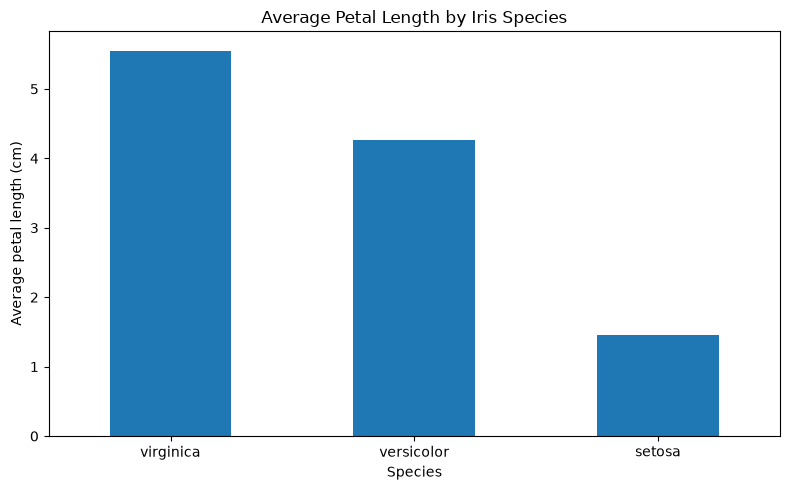

In [14]:
avg_petal = df.groupby("species")["petal_length_cm"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
avg_petal.plot(kind="bar")
plt.title("Average Petal Length by Iris Species")
plt.xlabel("Species")
plt.ylabel("Average petal length (cm)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 2. Line Chart — Average Measurements by Species

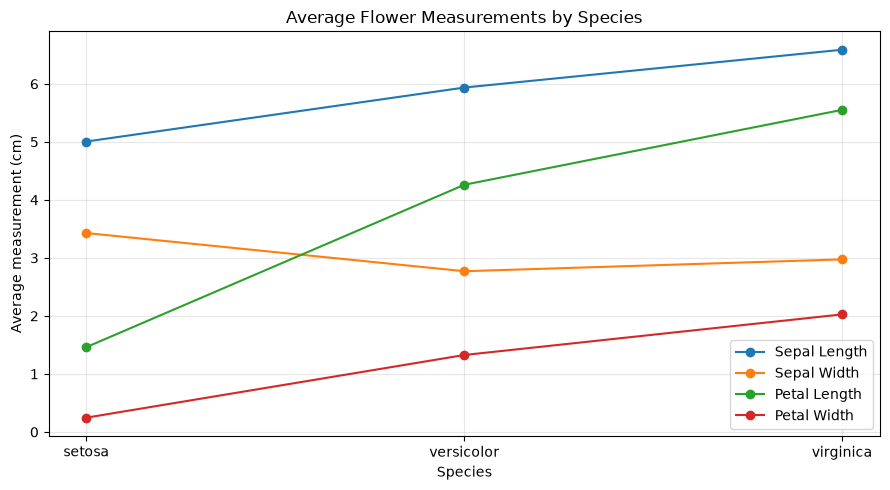

In [15]:
measurement_cols = ["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]
species_means = df.groupby("species")[measurement_cols].mean()

plt.figure(figsize=(9, 5))
for col in measurement_cols:
    plt.plot(species_means.index, species_means[col], marker="o", label=col.replace("_cm", "").replace("_", " ").title())
plt.title("Average Flower Measurements by Species")
plt.xlabel("Species")
plt.ylabel("Average measurement (cm)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Pie Chart — Records by Species

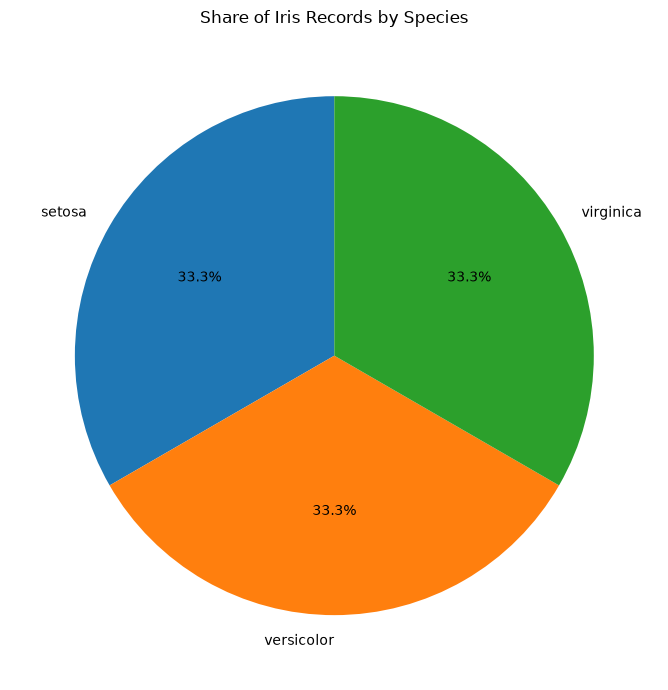

In [16]:
species_counts = df["species"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(species_counts, labels=species_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of Iris Records by Species")
plt.tight_layout()
plt.show()


## 4. Histogram — Petal Length Distribution

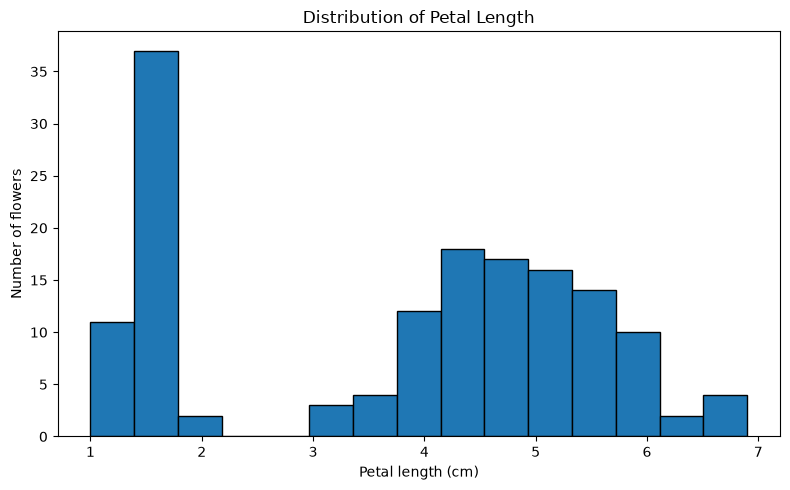

In [17]:
plt.figure(figsize=(8, 5))
plt.hist(df["petal_length_cm"], bins=15, edgecolor="black")
plt.title("Distribution of Petal Length")
plt.xlabel("Petal length (cm)")
plt.ylabel("Number of flowers")
plt.tight_layout()
plt.show()


## 5. Scatter Plot — Sepal Length vs. Petal Length

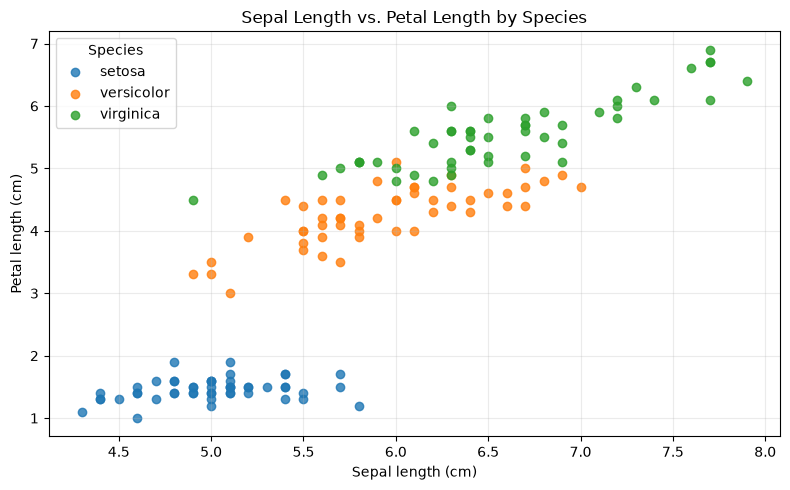

In [18]:
plt.figure(figsize=(8, 5))
for species, group in df.groupby("species"):
    plt.scatter(group["sepal_length_cm"], group["petal_length_cm"], label=species, alpha=0.8)
plt.title("Sepal Length vs. Petal Length by Species")
plt.xlabel("Sepal length (cm)")
plt.ylabel("Petal length (cm)")
plt.legend(title="Species")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


## 6. Bonus — Correlation Heatmap

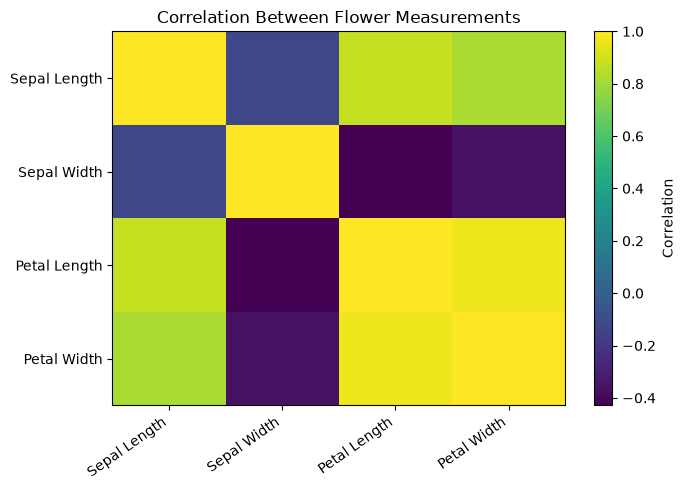

In [19]:
corr = df[measurement_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr, aspect="auto")
ax.set_xticks(range(len(corr.columns)), labels=[c.replace("_cm", "").replace("_", " ").title() for c in corr.columns], rotation=35, ha="right")
ax.set_yticks(range(len(corr.index)), labels=[c.replace("_cm", "").replace("_", " ").title() for c in corr.index])
ax.set_title("Correlation Between Flower Measurements")
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()


## Key Findings

Run the cells and use the charts to confirm these patterns:
- The dataset contains three species with equal record counts.
- Petal length and petal width differ noticeably across species.
- Sepal length and petal length generally show a positive relationship.
- The histogram shows how petal lengths are distributed across all flowers.

## Conclusion

The visualizations make it easier to compare species, understand measurement distributions, and spot relationships between flower features. For a submission, include screenshots of the charts and briefly describe two or three observations you see in your run.
